# Phase 2 — 평가지표 이론 + 통계적 베이스라인

이 노트북에서 할 일:
1. 혼동행렬 / precision / recall / F1 / macro-F1을 직접 손으로 계산해보고 sklearn과 비교
2. "전부 정상으로 예측" 베이스라인의 macro-F1이 왜 낮은지 직접 확인 (불균형 문제 체감)
3. Mahalanobis distance 기반 통계적 이상탐지 점수 계산
4. val에서 threshold를 스윕하면서 precision-recall curve와 macro-F1-vs-threshold 그래프로 최적 threshold 탐색
5. 첫 Dacon 리더보드 제출

Phase 1에서 train/val/test가 Kaggle Credit Card Fraud 데이터셋 기반이고, val 사기 30건은 전체 492건 중 일부라는 걸 확인했습니다. 여기서는 그 지식을 발판 삼아 "얼마나 잘 맞혔는지"를 재는 방법(평가지표)부터 제대로 이해하고 넘어갑니다.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 이 노트북은 01_EDA.ipynb와 별개의 실행 환경(커널)이라, 데이터를 다시 불러와야 합니다
train = pd.read_csv('../data/train.csv')
val = pd.read_csv('../data/val.csv')
test = pd.read_csv('../data/test.csv')
feature_cols = [c for c in train.columns if c.startswith('V')]

# 그래프 한글 깨짐 방지 설정 (01_EDA.ipynb에서 했던 것과 동일)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

print('train:', train.shape, '/ val:', val.shape, '/ test:', test.shape)

train: (113842, 31) / val: (28462, 32) / test: (142503, 31)


## 1. 혼동행렬(Confusion Matrix)이란?

정답(실제 Class)과 예측값을 비교해서 4가지 경우로 나눕니다.
- **TP** (True Positive): 실제 사기를 사기로 맞춤
- **TN** (True Negative): 실제 정상을 정상으로 맞춤
- **FP** (False Positive): 실제 정상인데 사기로 잘못 예측 (오탐)
- **FN** (False Negative): 실제 사기인데 정상으로 잘못 예측 (놓침, 이게 제일 치명적)

이 네 숫자로 precision, recall, F1을 계산합니다.
- **Precision(정밀도)** = TP / (TP+FP) — "사기라고 예측한 것 중 진짜 사기 비율"
- **Recall(재현율)** = TP / (TP+FN) — "실제 사기 중 우리가 찾아낸 비율"
- **F1** = precision과 recall의 조화평균 — 둘 다 어느 정도 챙겨야 높게 나옴

먼저 이 계산을 numpy로 직접 함수를 만들어서 구현합니다.

In [6]:
import numpy as np

def confusion_counts(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tp = np.sum((y_true == 1) & (y_pred == 1))  # 실제1, 예측1
    tn = np.sum((y_true == 0) & (y_pred == 0))  # 실제0, 예측0
    fp = np.sum((y_true == 0) & (y_pred == 1))  # 실제0인데 예측1 (오탐)
    fn = np.sum((y_true == 1) & (y_pred == 0))  # 실제1인데 예측0 (놓침)
    return tp, tn, fp, fn

def precision_recall_f1(y_true, y_pred):
    tp, tn, fp, fn = confusion_counts(y_true, y_pred)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return precision, recall, f1

## 2. 연습용 가짜 예측으로 함수 테스트

아직 모델이 없으니, 연습 삼아 **무작위로 사기 여부를 찍는 예측**을 만들어서 방금 만든 함수가 잘 작동하는지 확인합니다.
(실제 모델이 아니라 함수 검증용입니다.)

In [8]:
np.random.seed(42)  # 항상 같은 무작위 결과가 나오도록 시드 고정

y_true = val['Class'].values
y_pred_random = np.random.choice([0, 1], size=len(y_true), p=[0.5, 0.5])  # 50:50 확률로 무작위 예측

tp, tn, fp, fn = confusion_counts(y_true, y_pred_random)
precision, recall, f1 = precision_recall_f1(y_true, y_pred_random)

print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')
print(f'precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}')

TP=19, TN=14197, FP=14235, FN=11
precision=0.0013, recall=0.6333, f1=0.0027


## 3. sklearn과 비교 검증

직접 만든 함수의 결과가 sklearn의 공식 구현과 똑같이 나오는지 확인합니다.
(참고: sklearn의 `confusion_matrix`는 `[[TN, FP], [FN, TP]]` 순서로 출력됩니다 — 우리가 만든 것과 순서가 다르니 헷갈리지 않게 주의)

In [9]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

print('sklearn confusion_matrix [[TN, FP], [FN, TP]]:')
print(confusion_matrix(y_true, y_pred_random))
print()
print('sklearn precision:', precision_score(y_true, y_pred_random))
print('sklearn recall:', recall_score(y_true, y_pred_random))
print('sklearn f1:', f1_score(y_true, y_pred_random))

sklearn confusion_matrix [[TN, FP], [FN, TP]]:
[[14197 14235]
 [   11    19]]

sklearn precision: 0.0013329591693559703
sklearn recall: 0.6333333333333333
sklearn f1: 0.002660319238308597


## 4. macro-F1이란? — 불균형 데이터에서 accuracy의 함정

accuracy(정확도)는 "전체 중 맞춘 비율"이에요. 근데 사기가 0.105%뿐인 우리 데이터에서는,
**그냥 무조건 "정상"이라고만 찍어도 accuracy가 99.9%**가 나와요 — 뭔가 문제가 있죠.

**macro-F1**은 이 함정을 피하려고, 클래스별로(정상 F1, 사기 F1) 따로 F1을 구한 뒤 **단순 평균**을 냅니다.
클래스 크기와 무관하게 정상과 사기를 똑같은 비중으로 취급하기 때문에, 사기를 하나도 못 맞히면 점수가 확 떨어져요.

In [10]:
def macro_f1(y_true, y_pred):
    # 1(사기)을 양성으로 본 F1
    _, _, f1_class1 = precision_recall_f1(y_true, y_pred)
    # 라벨을 뒤집어서(0<->1) 0(정상)을 양성처럼 계산 -> 정상 클래스의 F1
    _, _, f1_class0 = precision_recall_f1(1 - y_true, 1 - y_pred)
    return (f1_class0 + f1_class1) / 2, f1_class0, f1_class1

## 5. "전부 정상으로 예측" 베이스라인의 실제 점수

가장 게으른 예측(무조건 정상)을 넣어서, accuracy와 macro-F1이 얼마나 다르게 나오는지 직접 확인합니다.

In [11]:
y_pred_all_normal = np.zeros_like(y_true)  # 무조건 정상(0)이라고 예측

accuracy = (y_true == y_pred_all_normal).mean()
macro_f1_score, f1_0, f1_1 = macro_f1(y_true, y_pred_all_normal)

print(f'accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'F1(정상=0 기준): {f1_0:.4f}')
print(f'F1(사기=1 기준): {f1_1:.4f}')
print(f'macro-F1: {macro_f1_score:.4f}')

accuracy: 0.9989 (99.89%)
F1(정상=0 기준): 0.9995
F1(사기=1 기준): 0.0000
macro-F1: 0.4997


## 6. sklearn과 최종 비교

sklearn의 `f1_score(..., average='macro')`로 같은 값이 나오는지 확인합니다.

In [12]:
from sklearn.metrics import f1_score, accuracy_score

print('sklearn accuracy:', accuracy_score(y_true, y_pred_all_normal))
print('sklearn macro f1:', f1_score(y_true, y_pred_all_normal, average='macro'))

sklearn accuracy: 0.9989459630384372
sklearn macro f1: 0.4997363518121419


## 7. 마할라노비스 거리 준비 — 평균 벡터와 공분산 행렬

train(정상 위주 데이터)을 기준으로 30개 변수(V1~V30)의 평균 벡터와 공분산 행렬을 구합니다.
이게 곧 "정상 거래는 대략 이런 모양이다"를 수학적으로 표현한 것입니다.

In [13]:
X_train = train[feature_cols].values  # (113842, 30) 크기의 배열로 변환
mu = X_train.mean(axis=0)             # 30개 변수 각각의 평균 (평균 벡터)
cov = np.cov(X_train, rowvar=False)   # 30x30 공분산 행렬 (rowvar=False: 행=샘플, 열=변수)
cov_inv = np.linalg.inv(cov)          # 공분산 행렬의 역행렬 (거리 계산에 필요)

print('mu shape:', mu.shape)
print('cov shape:', cov.shape)

mu shape: (30,)
cov shape: (30, 30)


## 8. 마할라노비스 거리 함수 직접 구현

공식 "D(x) = sqrt( (x-평균) x 공분산역행렬 x (x-평균) )" 를 모든 행에 대해 한 번에 계산하도록 벡터화해서 구현합니다.

In [14]:
def mahalanobis_distance(X, mu, cov_inv):
    diff = X - mu  # 각 행에서 평균을 뺌 (편차 벡터), 브로드캐스팅으로 전체 행에 한번에 적용
    left = diff @ cov_inv                     # (N, 30) @ (30, 30) = (N, 30)
    d_squared = np.sum(left * diff, axis=1)    # 행별로 (x-mu)^T cov_inv (x-mu) 계산
    return np.sqrt(d_squared)

train_dist = mahalanobis_distance(X_train, mu, cov_inv)
print('train 거리 예시 (앞 5개):', train_dist[:5])
print('train 거리 평균:', train_dist.mean(), '표준편차:', train_dist.std())

train 거리 예시 (앞 5개): [6.44603895 5.11176487 3.09089875 8.00420631 5.28391926]
train 거리 평균: 4.74956896190723 표준편차: 2.7278803406599317


## 9. scipy로 검증

scipy에는 이미 마할라노비스 거리 공식 함수가 있어요. 속도 때문에 앞 5개 행만 비교해서 우리 구현이 맞는지 확인합니다.

In [15]:
from scipy.spatial.distance import mahalanobis

for i in range(5):
    scipy_dist = mahalanobis(X_train[i], mu, cov_inv)
    print(f'행 {i}: 직접구현={train_dist[i]:.4f}, scipy={scipy_dist:.4f}')

행 0: 직접구현=6.4460, scipy=6.4460
행 1: 직접구현=5.1118, scipy=5.1118
행 2: 직접구현=3.0909, scipy=3.0909
행 3: 직접구현=8.0042, scipy=8.0042
행 4: 직접구현=5.2839, scipy=5.2839


## 10. val, test에도 마할라노비스 거리 적용

train으로 구한 평균(mu)과 공분산 역행렬(cov_inv)을 그대로 재사용해서 val, test 각 행의 거리를 계산합니다.
(val이나 test로 다시 mu, cov를 구하면 안 됩니다 — "정상 패턴의 기준"은 train 하나로 고정해야 공정한 비교가 됩니다.)

In [16]:
X_val = val[feature_cols].values
X_test = test[feature_cols].values

val_dist = mahalanobis_distance(X_val, mu, cov_inv)
test_dist = mahalanobis_distance(X_test, mu, cov_inv)

print('val 거리 예시 (앞 5개):', val_dist[:5])
print('test 거리 예시 (앞 5개):', test_dist[:5])

val 거리 예시 (앞 5개): [ 3.66924457  5.66137479  4.27812962  5.08400581 10.31326478]
test 거리 예시 (앞 5개): [3.4140622  3.20992746 4.38091487 3.97500403 6.06347861]


## 11. 정상 vs 사기의 거리 분포 비교

val은 실제 정답(Class)이 있으니, 정상 거래와 사기 거래의 마할라노비스 거리 분포가 실제로 다른지 히스토그램으로 확인합니다.
사기 쪽이 오른쪽(더 큰 거리)으로 몰려 있으면, 이 점수가 이상탐지에 쓸모있다는 뜻입니다.

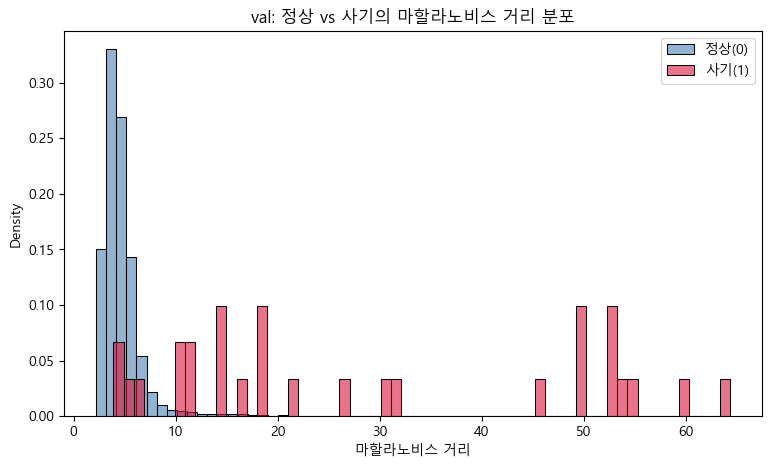

정상 평균 거리: 4.707864515565436
사기 평균 거리: 29.158992629824816


In [17]:
plt.figure(figsize=(9, 5))
sns.histplot(val_dist[val['Class'] == 0], bins=60, stat='density', label='정상(0)', color='steelblue', alpha=0.6)
sns.histplot(val_dist[val['Class'] == 1], bins=60, stat='density', label='사기(1)', color='crimson', alpha=0.6)
plt.xlabel('마할라노비스 거리')
plt.title('val: 정상 vs 사기의 마할라노비스 거리 분포')
plt.legend()
plt.show()

print('정상 평균 거리:', val_dist[val["Class"] == 0].mean())
print('사기 평균 거리:', val_dist[val["Class"] == 1].mean())

## 12. Threshold 스윕 — 최적의 기준선 찾기

val_dist의 최소~최대 범위를 500개 구간으로 나눠서, 각 threshold마다 "거리 >= threshold면 사기로 예측"했을 때의
macro-F1을 계산합니다. macro-F1이 가장 높은 지점이 우리가 찾는 최적 threshold입니다.

In [18]:
thresholds = np.linspace(val_dist.min(), val_dist.max(), 500)

macro_f1_scores = []
for t in thresholds:
    y_pred = (val_dist >= t).astype(int)  # 거리가 threshold 이상이면 사기(1)로 예측
    score, _, _ = macro_f1(y_true, y_pred)
    macro_f1_scores.append(score)

macro_f1_scores = np.array(macro_f1_scores)
best_idx = np.argmax(macro_f1_scores)
best_threshold = thresholds[best_idx]
best_macro_f1 = macro_f1_scores[best_idx]

print(f'최적 threshold: {best_threshold:.4f}')
print(f'그때 macro-F1: {best_macro_f1:.4f}')

최적 threshold: 48.7485
그때 macro-F1: 0.7324


## 13. Precision-Recall Curve와 Threshold-macroF1 곡선 시각화

왼쪽: recall(재현율)을 높이면 precision(정밀도)이 얼마나 희생되는지 보여주는 곡선.
오른쪽: threshold를 바꿔가며 macro-F1이 어떻게 변하는지, 그리고 우리가 찾은 최적점.

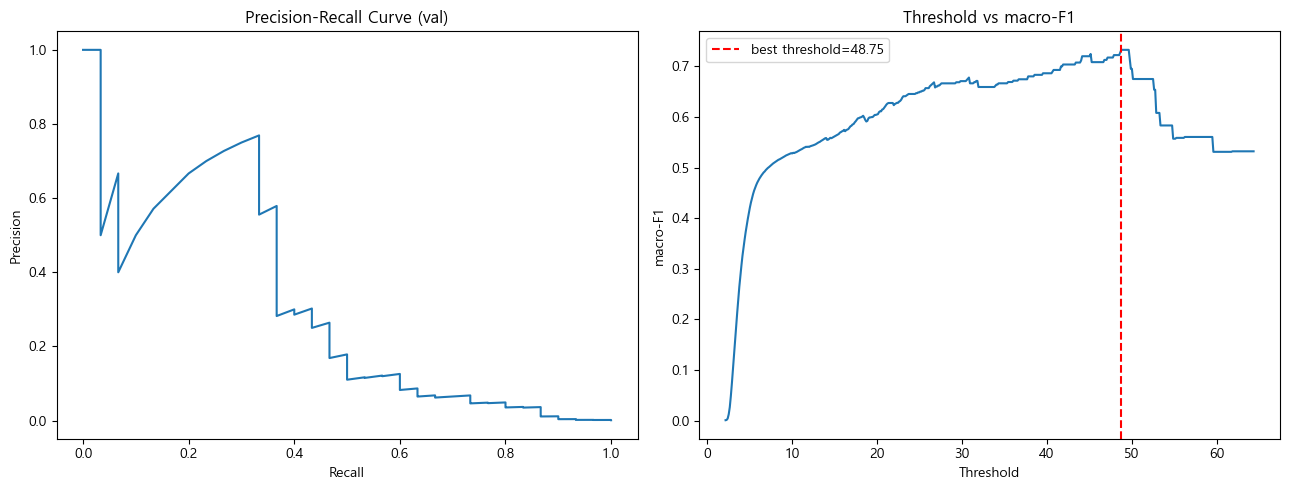

최적 threshold: 48.7485, 그때 macro-F1: 0.7324


In [19]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, pr_thresholds = precision_recall_curve(y_true, val_dist)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(recalls, precisions)
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve (val)')

axes[1].plot(thresholds, macro_f1_scores)
axes[1].axvline(best_threshold, color='red', linestyle='--', label=f'best threshold={best_threshold:.2f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('macro-F1')
axes[1].set_title('Threshold vs macro-F1')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f'최적 threshold: {best_threshold:.4f}, 그때 macro-F1: {best_macro_f1:.4f}')

## 14. test 예측 및 제출 파일 생성

val에서 찾은 최적 threshold(48 근처)를 test_dist에 그대로 적용해서 예측하고,
`sample_submission.csv`와 같은 형식(ID, Class)으로 제출 파일을 만듭니다.

In [20]:
test_pred = (test_dist >= best_threshold).astype(int)  # val에서 찾은 threshold를 test에 그대로 적용

print('test 중 사기로 예측한 건수:', test_pred.sum(), f'({test_pred.mean()*100:.3f}%)')

submission = pd.DataFrame({'ID': test['ID'], 'Class': test_pred})
display(submission.head())

submission.to_csv('../submissions/submission_phase2_mahalanobis.csv', index=False)
print('저장 완료: submissions/submission_phase2_mahalanobis.csv')

test 중 사기로 예측한 건수: 111 (0.078%)


,ID,Class
0,AAAA0x1,0
1,AAAA0x2,0
2,AAAA0x5,0
3,AAAA0x7,0
4,AAAA0xc,0


저장 완료: submissions/submission_phase2_mahalanobis.csv
